# 1. Exploring the data: inferential statistics and PCA

Before building any model, I start with the classical toolbox of my statistics course: describe the
sample, test simple hypotheses, then run a PCA on the indicators that will later feed the error model.

**Question.** Four land cover maps (ESA WorldCover, Dynamic World, Theia OSO, CLC+ Backbone) are
compared with 10,583 LUCAS field observations in four French regions. Where are the maps wrong, and can
indicators computed from the maps themselves tell us in advance?

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from alval.data import load_points, INDICATORS, PRODUCTS, REGIONS
from alval import plots

pd.set_option("display.precision", 3)
points = load_points()

In [2]:
points[["region", "lucas_class", "wc", "dw", "oso", "clc"] + INDICATORS].head()

,region,lucas_class,wc,dw,oso,clc,n_classes,heterogeneity,dominant_share,edge_distance,oso_confidence,dw_entropy
0,Occitanie,3,3,4,3,3,2,1,100,4,96,81
1,Occitanie,3,3,4,3,3,2,1,100,3,99,73
2,Occitanie,3,3,3,3,3,1,2,84,1,96,85
3,Occitanie,3,3,4,3,3,2,2,84,1,93,81
4,Occitanie,1,4,4,4,3,2,2,64,0,39,65


## Error rate of each map, with a 95% confidence interval

The error rate is a proportion, so its standard error is $\sqrt{\hat p(1-\hat p)/n}$.

In [3]:
rows = []
for region, d in points.groupby("region"):
    for code, name in PRODUCTS.items():
        p, n = d[f"err_{code}"].mean(), len(d)
        se = np.sqrt(p * (1 - p) / n)
        rows.append({"region": region, "map": name, "n": n, "error_rate": p,
                     "ci_low": p - 1.96 * se, "ci_high": p + 1.96 * se})
rates = pd.DataFrame(rows)
rates.pivot(index="region", columns="map", values="error_rate")

map,CLC+ Backbone,Dynamic World,ESA WorldCover,Theia OSO
region,,,,
Brittany,0.252,0.393,0.310,0.292
Grand Est,0.173,0.274,0.201,0.200
Massif Central,0.198,0.326,0.214,0.224
Occitanie,0.319,0.417,0.336,0.345


## Do error rates differ between regions?

Chi-square test of independence between the region and the error indicator, one map at a time.

In [4]:
tests = []
for code, name in PRODUCTS.items():
    table = pd.crosstab(points["region"], points[f"err_{code}"])
    chi2, p, dof, _ = stats.chi2_contingency(table)
    tests.append({"map": name, "chi2": chi2, "df": dof, "p_value": p})
pd.DataFrame(tests)

,map,chi2,df,p_value
0,ESA WorldCover,193.300,3,1.182e-41
1,Dynamic World,166.429,3,7.509e-36
2,Theia OSO,185.891,3,4.710e-40
3,CLC+ Backbone,192.844,3,1.483e-41


## PCA of the six indicators

Normed PCA (the indicators have different units). The error indicators of the four maps are added as
supplementary variables: they do not build the axes, but their correlations with the axes tell whether
the main gradients of the indicators are related to map errors.

In [5]:
from alval.pca import pca

X = points[INDICATORS]
sup = points[[f"err_{c}" for c in PRODUCTS]]
res = pca(X, supplementary=sup)
res.eig

,eigenvalue,percent,cumulative
Dim.1,3.189,53.148,53.148
Dim.2,0.846,14.093,67.241
Dim.3,0.668,11.126,78.367
Dim.4,0.616,10.260,88.627
Dim.5,0.496,8.263,96.890
Dim.6,0.187,3.110,100.000


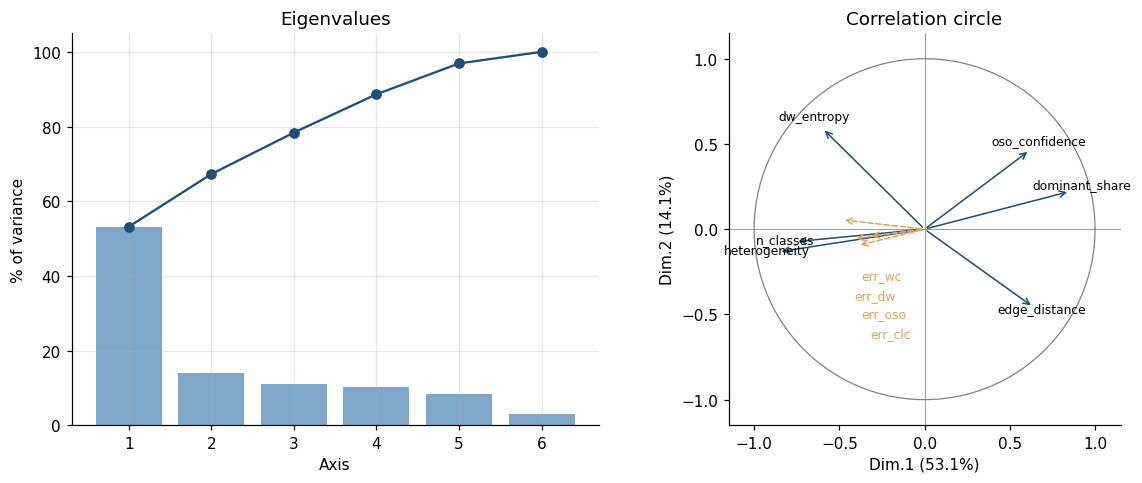

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
plots.scree(res, axes[0])
plots.correlation_circle(res, ax=axes[1])
fig.tight_layout()
fig.savefig("../reports/figures/pca.png", dpi=150, bbox_inches="tight")

### Quality of representation and contributions of the variables

In [7]:
pd.concat({"coord": res.var_coord.iloc[:, :2], "cos2": res.var_cos2.iloc[:, :2],
           "contrib (%)": res.var_contrib.iloc[:, :2]}, axis=1).round(2)

coord        cos2       contrib (%)       
               Dim.1 Dim.2 Dim.1 Dim.2       Dim.1  Dim.2
n_classes      -0.76 -0.07  0.58  0.01       18.05   0.63
heterogeneity  -0.86 -0.13  0.74  0.02       23.07   2.09
dominant_share  0.85  0.22  0.73  0.05       22.87   5.83
edge_distance   0.64 -0.46  0.41  0.21       12.78  24.70
oso_confidence  0.62  0.46  0.38  0.21       11.97  25.42
dw_entropy     -0.60  0.59  0.36  0.35       11.25  41.32

In [8]:
res.sup_coord.iloc[:, :2].round(2)

,Dim.1,Dim.2
err_wc,-0.42,-0.06
err_dw,-0.49,0.05
err_oso,-0.39,-0.10
err_clc,-0.33,-0.04


### Individuals

With 10,583 points the individual plot is mostly useful to see whether the errors of a map sit in a
particular part of the plane, and how well the points are represented (cos2 on the first plane).

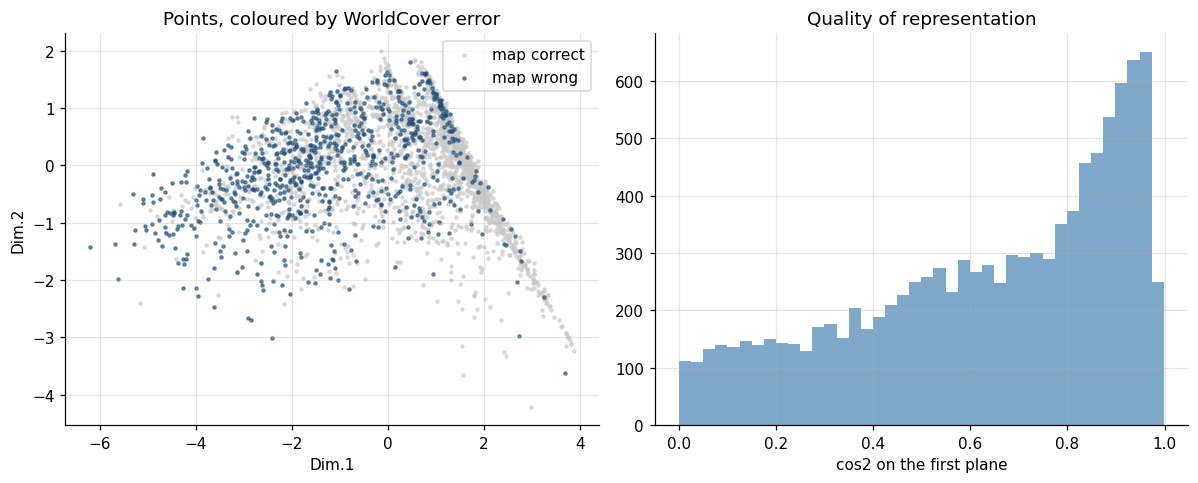

In [9]:
sample = res.ind_coord.sample(3000, random_state=0)
err = points.loc[sample.index, "err_wc"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for value, color, label in ((0, "#c9c9c9", "map correct"), (1, "#1f4e79", "map wrong")):
    s = sample[err == value]
    axes[0].scatter(s["Dim.1"], s["Dim.2"], s=4, c=color, label=label, alpha=0.6)
axes[0].set(xlabel="Dim.1", ylabel="Dim.2", title="Points, coloured by WorldCover error")
axes[0].legend()
quality = res.ind_cos2[["Dim.1", "Dim.2"]].sum(axis=1)
axes[1].hist(quality, bins=40, color="#7fa7c9")
axes[1].set(xlabel="cos2 on the first plane", title="Quality of representation")
fig.tight_layout()

## What I take from this

- **Error rates range from 17% to 42%.** Dynamic World is the least accurate map in every region,
  Grand Est is the "easiest" region and Occitanie the hardest.
- **The region matters**: the chi-square tests reject independence between region and error for all four
  maps (p < 1e-35). A model trained in some regions has to prove that it works in the others.
- **One main axis.** Only the first eigenvalue is above 1 (3.19, 53% of the variance; 67% on the first
  plane). Dim.1 opposes homogeneous, consensual landscapes (high share of the dominant class, far from
  boundaries, confident OSO) to heterogeneous ones (many classes around, products that disagree,
  uncertain Dynamic World). Dim.2 mostly separates the two confidence layers from the distance to edges.
- **Errors live on the heterogeneous side.** The error indicators of the four maps, projected as
  supplementary variables, correlate with Dim.1 between -0.33 and -0.49, and not with Dim.2. The
  indicators do carry information about where maps fail, which is what the next notebook models;
  the correlations are moderate, so errors will stay far from deterministic.